In [1]:
# --- bootstrap: dodaj katalog projektu do sys.path (dziala z notebooks/ i z root) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while not (_p / 'config.py').exists() and _p != _p.parent:
    _p = _p.parent
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))
import config


# Notebook 02: tematy i błędy klasyfikacji w czasie

Etap zestawia predykcje klasyfikatora z modelem tematycznym i opisuje, jak rozkład błędów zmienia się w czasie w obrębie tematu i wydawcy.

Wejście: `data/dane_z_prawdopodobienstwem.csv` z notebooka `01a` oraz zapisany model BERTopic z `01b`.
Wyjście: dwie tabele w `data/` i rysunek w `outputs/figures/`.

Logika siedzi w `src/evaluation.py` i `src/visualization.py`, notebook ją wywołuje i pokazuje wyniki.

## 1. Przeliczenie

Jedno wywołanie wczytuje predykcje, wczytuje zapisany model BERTopic, przypisuje tematy i liczy obie tabele błędów. Przypisanie tematów wymaga GPU i trwa kilka minut; wynik trafia do `data/valid_data_with_topics.csv` i przy kolejnych przebiegach jest stamtąd wczytywany, o ile liczba wierszy się zgadza. `force_transform=True` wymusza przeliczenie od nowa.

In [2]:
from src.evaluation import build_error_time_series

wyniki = build_error_time_series()

Korpus do analizy czasowej: 55914 naglowkow (2022-01-01 - 2026-02-04)


d:\ARTYKUL\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model t

Model BERTopic: models/bertopic_model_merged
Tematy z cache: valid_data_with_topics.csv (55914 wierszy)
Udzial naglowkow odstajacych: 15.6%
Zapisano dane_zle_sklasyfikowane_statystyki.csv: 1090 wierszy
Zapisano dane_wygladzone_miekkie.csv: 5204 wierszy


## 2. Twarde pomyłki

Twarda pomyłka to zdarzenie zero-jedynkowe: etykieta wydawcy różna od predykcji. Tabela podaje liczbę i udział pomyłek w miesiącu, osobno dla każdej pary wydawca-temat. Grupy poniżej 10 nagłówków są odrzucane, ponieważ udział policzony na kilku obserwacjach nie niesie informacji.

In [3]:
hard = wyniki["hard"]
print(f"Grup wydawca-temat-miesiąc: {len(hard)}")
hard.head(10)

Grup wydawca-temat-miesiąc: 1090


,label,topic,year,month,total_articles,misclassified_count,misclassified_percent,Name,Representation
2145,1,13,2025,5,20,16,80.000000,13_pl_niezalezna_dla_łysiak,"[pl, niezalezna, dla, łysiak, to, tomasz, się,..."
1852,1,4,2024,4,10,8,80.000000,4_morawiecki_premier_do_się,"[morawiecki, premier, do, się, na, nie, mateus..."
96,0,1,2025,11,20,14,70.000000,1_wybory_na_do_pis,"[wybory, na, do, pis, nie, czarzasty, krzyszto..."
4229,2,23,2024,5,29,20,68.965517,NaN,NaN
1740,1,1,2025,12,16,11,68.750000,1_wybory_na_do_pis,"[wybory, na, do, pis, nie, czarzasty, krzyszto..."
92,0,1,2025,7,21,14,66.666667,1_wybory_na_do_pis,"[wybory, na, do, pis, nie, czarzasty, krzyszto..."
1801,1,3,2023,10,15,10,66.666667,3_duda_prezydent_nawrocki_trump,"[duda, prezydent, nawrocki, trump, andrzej, pu..."
1807,1,3,2024,4,20,13,65.000000,3_duda_prezydent_nawrocki_trump,"[duda, prezydent, nawrocki, trump, andrzej, pu..."
2434,1,23,2024,6,20,13,65.000000,NaN,NaN
1820,1,3,2025,6,11,7,63.636364,3_duda_prezydent_nawrocki_trump,"[duda, prezydent, nawrocki, trump, andrzej, pu..."


## 3. Oczekiwana liczba błędów

Pojedynczy temat w pojedynczym miesiącu zbiera na tyle mało nagłówków, że szereg twardych pomyłek skacze między zerem a kilkoma zdarzeniami i nie daje się odczytać jako przebieg. Zamiast zliczania pomyłek wkład nagłówka liczy się więc jako P(błąd) = 1 - P(klasa prawdziwa), czyli prawdopodobieństwo, które klasyfikator rozłożył na pozostałych wydawców. Suma po nagłówkach miesiąca daje oczekiwaną liczbę błędów, zmieniającą się płynnie.

Miara opisuje niepewność klasyfikatora wobec nagłówka, nie rozstrzyga natomiast, czy nagłówek został przypisany błędnie. To pokazuje tabela twardych pomyłek wyżej.

In [4]:
soft = wyniki["soft"]
print(f"Wierszy: {len(soft)} | oczekiwanych błędów łącznie: "
      f"{soft['misclassified_count'].sum():.0f} z {soft['total_articles'].sum():.0f} nagłówków")
soft.head(10)

Wierszy: 5204 | oczekiwanych błędów łącznie: 14077 z 47208 nagłówków


,month_str,label,topic,total_articles,misclassified_count,misclassified_percent,date_parsed,year,month
0,2022-01,0,0,23,3.102721,13.490093,2022-01-01,2022,1
1,2022-01,0,1,5,2.193244,43.864887,2022-01-01,2022,1
2,2022-01,0,2,6,0.618976,10.316273,2022-01-01,2022,1
3,2022-01,0,3,8,3.850175,48.127191,2022-01-01,2022,1
4,2022-01,0,4,3,0.771284,25.709483,2022-01-01,2022,1
5,2022-01,0,5,2,0.516843,25.842154,2022-01-01,2022,1
6,2022-01,0,6,31,8.175889,26.373835,2022-01-01,2022,1
7,2022-01,0,7,1,0.476930,47.692960,2022-01-01,2022,1
8,2022-01,0,8,4,1.470861,36.771516,2022-01-01,2022,1
9,2022-01,0,10,5,1.672532,33.450646,2022-01-01,2022,1


## 4. Błędy w czasie według tematu i wydawcy

Panel na temat, seria na wydawcę. Zacieniony pas po prawej to zbiór testowy, czyli ostatni rok korpusu; granicę odczytano ze `split_info.json`.

Barwy wydawców są wspólne dla wszystkich rysunków projektu i pochodzą z `src/plot_style.py`. Informacja siedzi także w kroju linii, więc rysunek zachowuje sens w druku czarno-białym.

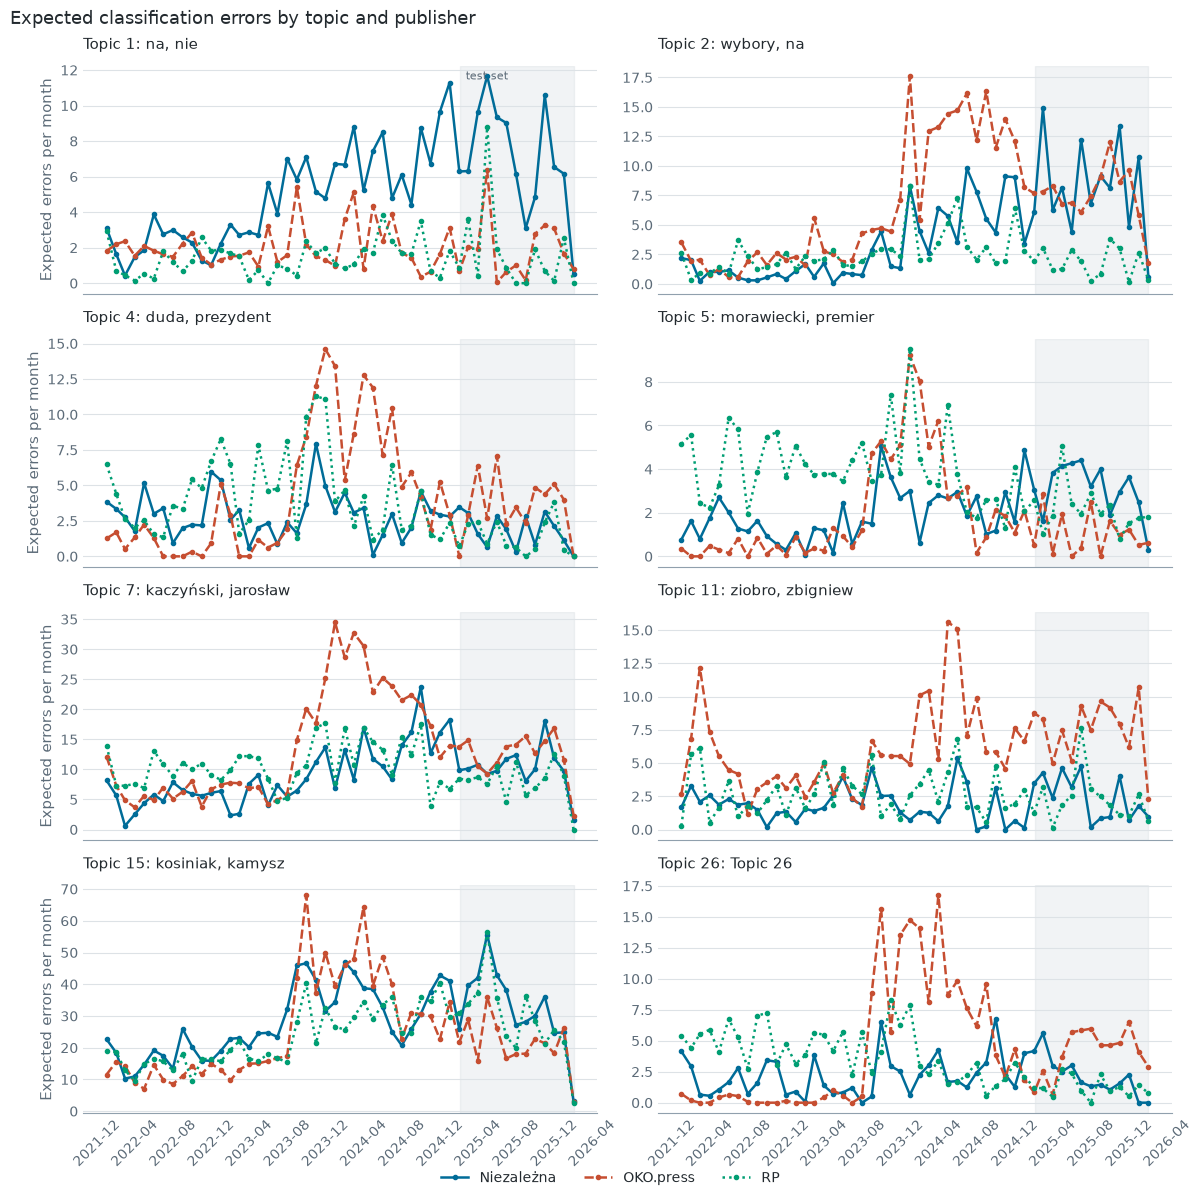

In [5]:
from src.visualization import plot_topic_error_series

fig = plot_topic_error_series(
    wyniki["soft"],
    topic_model=wyniki["topic_model"],
    max_topics=8,
    save_path=config.FIGURES / "04_bledy_wedlug_tematu_w_czasie.png",
)